# 05 · PBL 1 — Weekly Demand Forecasting with Linear, Ridge and Bayesian Regression
**Units 1 and 2.** Run `01_Create_Dataset` first. Reads `dataset/` · creates `dataset/store_weekly.csv` and `Unit_1_2_PBL1_Data_and_Regression/results/05_regression/`.

**Task:** forecast next week's number of food orders of every dark store, so the central warehouse can plan each
store's weekly replenishment. A forecast for week *t* may only use information available at the end of week *t − 1*.

In [1]:
# ---- Only on Google Colab (skip on your own computer) ----
# !pip install -q hmmlearn
# from google.colab import drive; drive.mount("/content/drive")
# %cd /content/drive/MyDrive/QuickCommerce_ML_Project_Final

import os, json, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, Ridge, BayesianRidge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# project root = the folder that contains data/ and dataset/ (works from the unit folder, the root or Colab)
if not os.path.isdir("data") and os.path.isdir(os.path.join("..", "data")):
    os.chdir("..")
print("Working folder:", os.getcwd())
warnings.filterwarnings("ignore")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
DATE = "%d-%m-%Y"

def inr(x):
    # Indian digit grouping: 113390 -> 1,13,390
    s = f"{abs(x):.0f}"; head, tail = s[:-3], s[-3:]; parts = []
    while len(head) > 2:
        parts.insert(0, head[-2:]); head = head[:-2]
    if head: parts.insert(0, head)
    return ("-" if x < 0 else "") + ",".join(parts + [tail])

# chart style — colour-blind-safe palette in fixed order
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 9.5, "font.size": 8.5, "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 1.5, "figure.dpi": 110, "legend.frameon": False,
})

OUT = "Unit_1_2_PBL1_Data_and_Regression/results/05_regression"                      # every file this notebook creates goes here
os.makedirs(OUT, exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=240, bbox_inches="tight")
    plt.show()

Working folder: /home/claude/project


## 5.1 Building the store-week dataset
- Orders are counted per **store and week** (weeks start on Monday). A store's first, partly open week and the last,
  incomplete week of the data are removed.
- **Features** (all known before the week starts):

| Feature | Meaning |
|---|---|
| `lag1`, `lag2`, `lag4` | orders of the same store 1, 2 and 4 weeks earlier |
| `roll4` | average orders of the previous 4 weeks |
| `store_age_w` | weeks since the store opened (captures growth) |
| `festival_days` | number of festival days in the week (known from the calendar) |
| `monsoon` | 1 for June–October weeks |
| `area_*` | location type of the store (one-hot encoded; Office / Tech Park is the reference) |

In [2]:
clean = pd.read_csv("dataset/clean_food_orders.csv", parse_dates=["order_date"])
stores = pd.read_csv("dataset/store_features.csv", index_col="store_id", parse_dates=["first_order"])
clean["week"] = clean.order_date - pd.to_timedelta(clean.order_date.dt.weekday, unit="D")
counts = clean.groupby(["store_id", "week"]).size()
all_weeks = pd.date_range(clean.week.min(), clean.week.max(), freq="7D")
fest_days = clean[~clean.event.eq("Regular day")].groupby("week").order_date.nunique()

rows = []
for s in stores.index:
    first_week = stores.loc[s, "first_order"] - pd.Timedelta(days=stores.loc[s, "first_order"].weekday())
    weeks = all_weeks[all_weeks > first_week]                       # drop the partly open first week
    rows.append(pd.DataFrame({"store_id": s, "week": weeks,
                              "orders": counts.reindex(pd.MultiIndex.from_product([[s], weeks]), fill_value=0).values}))
weekly = pd.concat(rows)
weekly = weekly[weekly.week < pd.Timestamp("2026-09-28")]          # last complete week starts 21-09-2026
weekly = weekly.sort_values(["store_id", "week"]).reset_index(drop=True)
g = weekly.groupby("store_id").orders
weekly["lag1"], weekly["lag2"], weekly["lag4"] = g.shift(1), g.shift(2), g.shift(4)
weekly["roll4"] = g.transform(lambda s: s.shift(1).rolling(4).mean())
weekly["store_age_w"] = weekly.groupby("store_id").cumcount()
weekly["festival_days"] = weekly.week.map(fest_days).fillna(0).astype(int)
weekly["monsoon"] = weekly.week.dt.month.isin([6, 7, 8, 9, 10]).astype(int)
weekly["area_type"] = weekly.store_id.map(stores.area_type)
weekly = pd.get_dummies(weekly, columns=["area_type"], prefix="area", dtype=int).drop(columns="area_Office / Tech Park")
weekly = weekly.dropna().reset_index(drop=True)
FEATURES = ["lag1", "lag2", "lag4", "roll4", "store_age_w", "festival_days", "monsoon",
            "area_Premium Residential", "area_Residential", "area_Student / PG Hub"]
weekly.to_csv("dataset/store_weekly.csv", index=False)
print(f"Store-week rows: {inr(len(weekly))}  |  stores: {weekly.store_id.nunique()}  |  "
      f"weeks: {weekly.week.min():{DATE}} to {weekly.week.max():{DATE}}")
weekly[["store_id", "week", "orders"] + FEATURES].head()

Store-week rows: 4,039  |  stores: 58  |  weeks: 03-02-2025 to 21-09-2026


,store_id,week,orders,lag1,lag2,lag4,roll4,store_age_w,festival_days,monsoon,area_Premium Residential,area_Residential,area_Student / PG Hub
0,DS001,2025-02-03,20,20.000,17.000,12.000,17.500,4,0,0,0,0,1
1,DS001,2025-02-10,26,20.000,20.000,21.000,19.500,5,2,0,0,0,1
2,DS001,2025-02-17,19,26.000,20.000,17.000,20.750,6,0,0,0,0,1
3,DS001,2025-02-24,25,19.000,26.000,20.000,21.250,7,0,0,0,0,1
4,DS001,2025-03-03,26,25.000,19.000,20.000,22.500,8,0,0,0,0,1


## 5.2 Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
orders,"4,039.000",26.920,13.430,1.000,17.000,25.000,35.000,92.000
lag1,"4,039.000",26.650,13.370,1.000,17.000,25.000,35.000,92.000
lag2,"4,039.000",26.360,13.300,1.000,17.000,25.000,34.000,92.000
lag4,"4,039.000",25.700,13.160,0.000,16.000,24.000,34.000,92.000
roll4,"4,039.000",26.190,12.310,2.250,17.000,24.500,34.000,75.250
store_age_w,"4,039.000",40.780,23.520,4.000,21.000,38.000,59.000,89.000
festival_days,"4,039.000",0.240,0.710,0.000,0.000,0.000,0.000,3.000


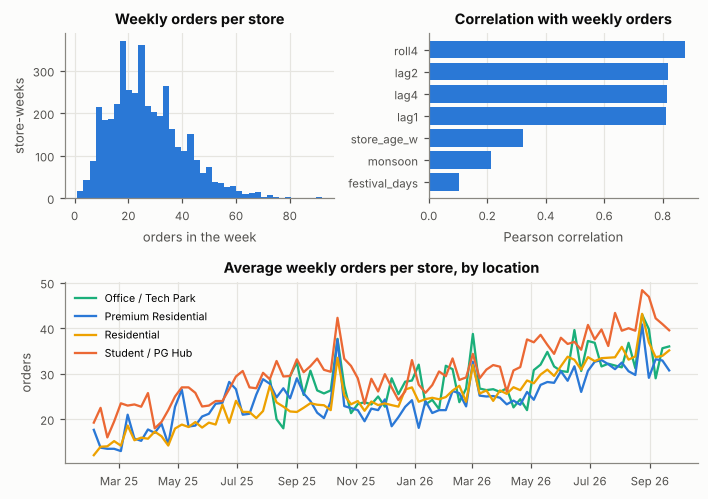

Mean weekly orders — festival weeks vs other weeks: {'other': 26.6, 'festival': 29.5}


In [3]:
display(weekly[["orders"] + FEATURES[:6]].describe().T.round(2))
fig = plt.figure(figsize=(6.5, 4.6)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, :]), fig.add_subplot(gs[0, 1])]
axes[0].hist(weekly.orders, bins=40, color=BLUE)
axes[0].set(title="Weekly orders per store", xlabel="orders in the week", ylabel="store-weeks")
area = clean.groupby("store_id").area_type.first()
by_area = weekly.assign(area=weekly.store_id.map(area)).groupby(["week", "area"]).orders.mean().unstack()
for col, colour in zip(by_area.columns, [AQUA, BLUE, YELLOW, ORANGE]):
    axes[1].plot(by_area.index, by_area[col], color=colour, lw=1.5, label=col)
axes[1].set(title="Average weekly orders per store, by location", ylabel="orders")
axes[1].legend(fontsize=7); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
corr = weekly[["orders"] + FEATURES[:7]].corr()["orders"].drop("orders").sort_values()
axes[2].barh(corr.index, corr.values, color=[BLUE if v > 0 else ORANGE for v in corr.values])
axes[2].set(title="Correlation with weekly orders", xlabel="Pearson correlation"); axes[2].grid(axis="y", visible=False)
plt.tight_layout(); save_fig(fig, "eda_weekly")
print("Mean weekly orders — festival weeks vs other weeks:",
      weekly.groupby(weekly.festival_days > 0).orders.mean().round(1).rename({False: "other", True: "festival"}).to_dict())

## 5.3 Train/test split and scaling
The data is a time series, so it is split **by time, not randomly**: the model is trained on the past and tested on
the following six months it has never seen. Scaling (z-score) is fitted on the training weeks only, so no
information from the test period leaks into training.

In [4]:
SPLIT = pd.Timestamp("2026-03-30")
train, test = weekly[weekly.week < SPLIT], weekly[weekly.week >= SPLIT]
X_train, X_test, y_train, y_test = train[FEATURES], test[FEATURES], train.orders, test.orders
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
print(f"Train: {inr(len(train))} store-weeks ({train.week.min():{DATE}} to {train.week.max():{DATE}})")
print(f"Test : {inr(len(test))} store-weeks ({test.week.min():{DATE}} to {test.week.max():{DATE}}, {test.week.nunique()} weeks)")

Train: 2,531 store-weeks (03-02-2025 to 23-03-2026)
Test : 1,508 store-weeks (30-03-2026 to 21-09-2026, 26 weeks)


## 5.4 Models
| Model | Idea | Formula |
|---|---|---|
| Naive baseline | next week = this week | $\hat y_t = y_{t-1}$ |
| Linear Regression (OLS) | least-squares straight-line fit | $\min_w \lVert y - Xw\rVert^2$ |
| Ridge Regression | OLS + L2 penalty that shrinks weights; α chosen by time-series cross-validation | $\min_w \lVert y - Xw\rVert^2 + \alpha\lVert w\rVert^2$ |
| Bayesian Linear Regression | Gaussian prior on the weights; gives a predictive mean **and** uncertainty | $w \sim \mathcal N(0, \lambda^{-1}I)$, $y \mid w \sim \mathcal N(Xw, \alpha^{-1})$ |

In [5]:
def metrics(y, p):
    return {"MAE": float(mean_absolute_error(y, p)), "RMSE": float(mean_squared_error(y, p) ** 0.5),
            "R²": float(r2_score(y, p)), "WAPE": float(np.abs(y - p).sum() / y.sum())}
pred = pd.DataFrame({"store_id": test.store_id, "week": test.week, "actual": y_test})
pred["Naive (last week)"] = X_test.lag1.values

ols = LinearRegression().fit(Xs_train, y_train)
pred["Linear Regression"] = ols.predict(Xs_test)

tscv = TimeSeriesSplit(n_splits=5)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 25), cv=tscv).fit(Xs_train, y_train)
pred["Ridge Regression"] = ridge.predict(Xs_test)

bayes = BayesianRidge().fit(Xs_train, y_train)
mu, sd = bayes.predict(Xs_test, return_std=True)
pred["Bayesian Regression"], pred["bayes_sd"] = mu, sd

MODELS = ["Naive (last week)", "Linear Regression", "Ridge Regression", "Bayesian Regression"]
results = pd.DataFrame({m: metrics(y_test, pred[m]) for m in MODELS}).T
results.to_csv(f"{OUT}/metrics.csv")
print(f"Ridge α chosen by 5-fold time-series CV: {ridge.alpha_:g} (smallest value tried: {ridge.alphas.min():g})")
print(f"Bayesian: noise precision α = {bayes.alpha_:.4f}, weight precision λ = {bayes.lambda_:.4f}")
coverage = ((y_test >= mu - 1.96 * sd) & (y_test <= mu + 1.96 * sd)).mean()
print(f"Bayesian 95% prediction interval covers {coverage:.1%} of test weeks")
results.round(3)

Ridge α chosen by 5-fold time-series CV: 0.001 (smallest value tried: 0.001)
Bayesian: noise precision α = 0.0295, weight precision λ = 0.1508
Bayesian 95% prediction interval covers 90.6% of test weeks


,MAE,RMSE,R²,WAPE
Naive (last week),6.761,8.918,0.644,0.207
Linear Regression,5.353,6.970,0.782,0.164
Ridge Regression,5.353,6.970,0.782,0.164
Bayesian Regression,5.356,6.975,0.782,0.164


,Linear,Ridge,Bayesian
lag1,0.100,0.100,0.330
lag2,0.460,0.460,0.680
lag4,0.390,0.390,0.620
roll4,8.420,8.410,7.790
store_age_w,-0.300,-0.300,-0.290
festival_days,1.870,1.870,1.870
monsoon,0.200,0.200,0.200
area_Premium Residential,-0.060,-0.060,-0.060
area_Residential,-0.110,-0.110,-0.110
area_Student / PG Hub,0.150,0.150,0.150


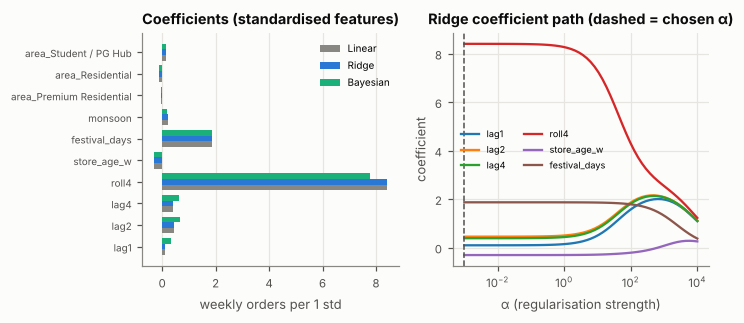

In [6]:
coef = pd.DataFrame({"Linear": ols.coef_, "Ridge": ridge.coef_, "Bayesian": bayes.coef_}, index=FEATURES)
coef.round(3).to_csv(f"{OUT}/coefficients.csv")
display(coef.round(2))
alphas = np.logspace(-3, 4, 60)
path = np.array([Ridge(alpha=a).fit(Xs_train, y_train).coef_ for a in alphas])
fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.0))
y_pos = np.arange(len(FEATURES))
for i, (name, colour) in enumerate(zip(coef.columns, [MUTED, BLUE, AQUA])):
    axes[0].barh(y_pos + (i - 1) * 0.26, coef[name], 0.26, color=colour, label=name)
axes[0].set_yticks(y_pos); axes[0].set_yticklabels(FEATURES, fontsize=6.5)
axes[0].set(title="Coefficients (standardised features)", xlabel="weekly orders per 1 std")
axes[0].legend(fontsize=6.5); axes[0].grid(axis="y", visible=False)
for j, f in enumerate(FEATURES[:6]):
    axes[1].plot(alphas, path[:, j], label=f)
axes[1].axvline(ridge.alpha_, color=INK2, ls="--", lw=1)
axes[1].set_xscale("log"); axes[1].legend(fontsize=6, ncol=2)
axes[1].set(title="Ridge coefficient path (dashed = chosen α)", xlabel="α (regularisation strength)", ylabel="coefficient")
plt.tight_layout(); save_fig(fig, "coefficients")

## 5.5 Results and evaluation

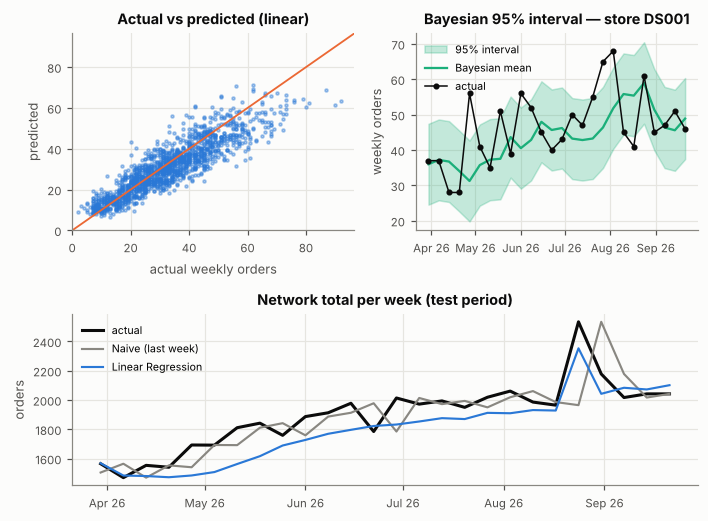

Residuals: mean +1.67, std 6.77


In [7]:
best = pred["Linear Regression"]
fig = plt.figure(figsize=(6.5, 4.8)); gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1])
axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, :]), fig.add_subplot(gs[0, 1])]
axes[0].scatter(y_test, best, s=4, alpha=0.4, color=BLUE)
lim = [0, y_test.max() * 1.05]; axes[0].plot(lim, lim, color=ORANGE, lw=1.2)
axes[0].set(title="Actual vs predicted (linear)", xlabel="actual weekly orders", ylabel="predicted", xlim=lim, ylim=lim)
net = pred.groupby("week")[["actual"] + MODELS].sum()
axes[1].plot(net.index, net.actual, color=INK, lw=2, label="actual")
for m_, colour in zip(MODELS, [MUTED, BLUE, AQUA, YELLOW]):
    if m_ in ("Naive (last week)", "Linear Regression"):
        axes[1].plot(net.index, net[m_], color=colour, lw=1.4, label=m_)
axes[1].set(title="Network total per week (test period)", ylabel="orders"); axes[1].legend(fontsize=7)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
s_id = pred.store_id.value_counts().index[0]
one = pred[pred.store_id == s_id]
axes[2].fill_between(one.week, one["Bayesian Regression"] - 1.96 * one.bayes_sd, one["Bayesian Regression"] + 1.96 * one.bayes_sd,
                     color=AQUA, alpha=0.25, label="95% interval")
axes[2].plot(one.week, one["Bayesian Regression"], color=AQUA, label="Bayesian mean")
axes[2].plot(one.week, one.actual, color=INK, marker="o", ms=3, lw=1, label="actual")
axes[2].set(title=f"Bayesian 95% interval — store {s_id}", ylabel="weekly orders"); axes[2].legend(fontsize=7)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
plt.tight_layout(); save_fig(fig, "forecast_results")
resid = y_test - best
print(f"Residuals: mean {resid.mean():+.2f}, std {resid.std():.2f}")

In [8]:
pred.round(3).to_csv(f"{OUT}/test_predictions.csv", index=False)
joblib.dump({"scaler": scaler, "linear": ols, "ridge": ridge, "bayes": bayes, "features": FEATURES}, f"{OUT}/regression_models.joblib")
json.dump({"split": f"{SPLIT:{DATE}}", "train_rows": len(train), "test_rows": len(test), "ridge_alpha": float(ridge.alpha_),
           "bayes_coverage_95": float(coverage), **{f"{m}|{k}": round(float(v), 4) for m in MODELS for k, v in results.loc[m].items()}},
          open(f"{OUT}/summary.json", "w"), indent=2)
for f in sorted(os.listdir(OUT)):
    print(f"{OUT}/{f}")

Unit_1_2_PBL1_Data_and_Regression/results/05_regression/coefficients.csv
Unit_1_2_PBL1_Data_and_Regression/results/05_regression/coefficients.png
Unit_1_2_PBL1_Data_and_Regression/results/05_regression/eda_weekly.png
Unit_1_2_PBL1_Data_and_Regression/results/05_regression/forecast_results.png
Unit_1_2_PBL1_Data_and_Regression/results/05_regression/metrics.csv
Unit_1_2_PBL1_Data_and_Regression/results/05_regression/regression_models.joblib
Unit_1_2_PBL1_Data_and_Regression/results/05_regression/summary.json
Unit_1_2_PBL1_Data_and_Regression/results/05_regression/test_predictions.csv


## 5.6 Interpretation
- All three regression models clearly beat the naive "same as last week" forecast (lower MAE and RMSE, higher R²).
- Linear, Ridge and Bayesian regression give almost identical accuracy: with 2,531 training rows and only 10
  features there is no overfitting for regularisation to remove — cross-validation picks the smallest α tried (0.001)
  and Bayesian shrinkage is mild.
- The 4-week average (`roll4`) carries most of the signal; each festival day adds about two orders to a store's week.
- Residuals are on average +1.7 orders: the business kept growing in the test period, so all models slightly
  under-forecast.
- The Bayesian model also gives a 95% prediction interval — useful for setting safety stock.

## Readings used in the report
Every number quoted in the report (Chapter 3 – Sections 3.4 and 3.7) that is not already shown above is printed here, computed from this notebook's own results.

In [9]:
print("Pearson correlation with weekly orders [Figure 3.3]")
print(corr.round(2).to_string())
print(f"\nBayesian ridge evidence: noise precision alpha = {bayes.alpha_:.4f} (noise std = {bayes.alpha_ ** -0.5:.1f} orders), "
      f"weight precision lambda = {bayes.lambda_:.4f}")
print(f"Ridge penalty chosen by time-series CV: alpha = {ridge.alpha_:g}")

Pearson correlation with weekly orders [Figure 3.3]
festival_days   0.100
monsoon         0.210
store_age_w     0.320
lag1            0.810
lag4            0.810
lag2            0.820
roll4           0.880

Bayesian ridge evidence: noise precision alpha = 0.0295 (noise std = 5.8 orders), weight precision lambda = 0.1508
Ridge penalty chosen by time-series CV: alpha = 0.001
